#### **Automotive After-Sales: Customer Retention & Lifecycle Segmentation**
* This notebook segments customers into actionable behavioral lifecycle groups (Active, At-Risk, Lapsed, Lost) based on recency of service visits, lifetime spend, and vehicle ownership data.

#### **Imports**

In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import os
from datetime import datetime, timedelta

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

print("Libraries loaded successfully!")

Libraries loaded successfully!


#### **Load Raw Data**

* Loading customer, vehicle, booking, and repair order tables.

In [2]:
DATA_DIR = "../data/raw"

df_customers = pd.read_parquet(os.path.join(DATA_DIR, "dim_customers.parquet"))
df_vehicles = pd.read_parquet(os.path.join(DATA_DIR, "dim_vehicles.parquet"))
df_bookings = pd.read_parquet(os.path.join(DATA_DIR, "fact_bookings.parquet"))
df_repair_orders = pd.read_parquet(os.path.join(DATA_DIR, "fact_repair_orders.parquet"))

print(f"Customers loaded: {df_customers.shape}")
print(f"Vehicles loaded: {df_vehicles.shape}")
print(f"Repair Orders loaded: {df_repair_orders.shape}")

Customers loaded: (60000, 5)
Vehicles loaded: (75000, 8)
Repair Orders loaded: (120000, 12)


#### **Feature Engineering**

##### **Customer Service History & Recency Feature Engineering**
* Compute days since last service, total lifetime spend (Labor + Parts), visit frequency, and average declined work value per customer relative to a reference date of January 1, 2026.

#### **Aggregating Customer History**

In [3]:
# Link repair orders to bookings to retrieve appointment dates and customer IDs
ro_full = df_repair_orders.merge(
    df_bookings[["booking_id", "customer_id", "vin", "appointment_date"]],
    on="booking_id",
    how="inner"
)
ro_full["total_spend_aed"] = ro_full["labor_revenue_aed"] + ro_full["parts_revenue_aed"]

# Reference date for recency calculation
reference_date = pd.to_datetime("2026-01-01")

cust_history = ro_full.groupby("customer_id").agg(
    last_service_date=("appointment_date", "max"),
    total_service_visits=("ro_id", "count"),
    lifetime_spend_aed=("total_spend_aed", "sum"),
    avg_declined_work_aed=("declined_work_value_aed", "mean")
).reset_index()

cust_history["days_since_last_service"] = (reference_date - pd.to_datetime(cust_history["last_service_date"])).dt.days

# Merge back with customer profile
df_cust_profile = df_customers.merge(cust_history, on="customer_id", how="left")
df_cust_profile["last_service_date"] = df_cust_profile["last_service_date"].fillna(pd.to_datetime("2023-01-01"))
df_cust_profile["days_since_last_service"] = df_cust_profile["days_since_last_service"].fillna(1095)
df_cust_profile["total_service_visits"] = df_cust_profile["total_service_visits"].fillna(0)
df_cust_profile["lifetime_spend_aed"] = df_cust_profile["lifetime_spend_aed"].fillna(0.0)
df_cust_profile["avg_declined_work_aed"] = df_cust_profile["avg_declined_work_aed"].fillna(0.0)

print("Customer Profile Aggregation Complete. Shape:", df_cust_profile.shape)
display(df_cust_profile.head())

Customer Profile Aggregation Complete. Shape: (60000, 10)


,customer_id,emirate,customer_type,acquisition_channel,crm_consent,last_service_date,total_service_visits,lifetime_spend_aed,avg_declined_work_aed,days_since_last_service
0,CUST-000001,Al Ain,Retail Individual,Digital App,1,2023-05-14,1.00,4363.73,0.00,963.00
1,CUST-000002,Ajman,Fleet Corporate,Showroom Walk-in,1,2025-07-04,3.00,7640.35,1590.31,181.00
2,CUST-000003,Sharjah,Fleet Corporate,Call Center Campaign,1,2023-10-21,3.00,9304.71,658.19,803.00
3,CUST-000004,Abu Dhabi,Retail Individual,Web Inquiry,1,2023-05-11,1.00,1064.29,0.00,966.00
4,CUST-000005,Dubai,Retail Individual,Web Inquiry,0,2025-08-17,1.00,4168.29,0.00,137.00


#### **Lifecycle Segmentation Rules**

##### **Lifecycle Segmentation Classification**
Customers are classified into strategic groups to prioritize retention campaigns:
- **Active Fleet (0–6 months):** Recently serviced customers.
- **Due / Maintenance Window (6–12 months):** Approaching service interval.
- **At-Risk Lapsing (12–18 months):** High priority for CRM follow-up.
- **Lapsed (18–24 months):** Critical intervention required.
- **Defected / Lost (>24 months):** Dormant / churned.

#### **Applying Segmentation Rules & Saving Processed Data**

In [4]:
def classify_customer_segment(row):
    days = row["days_since_last_service"]
    if days <= 180:
        return "Active Fleet (0-6m)"
    elif 180 < days <= 365:
        return "Due / Maintenance Window (6-12m)"
    elif 365 < days <= 548:
        return "At-Risk Lapsing (12-18m)"
    elif 548 < days <= 730:
        return "Lapsed (18-24m)"
    else:
        return "Defected / Lost (>24m)"

df_cust_profile["lifecycle_segment"] = df_cust_profile.apply(classify_customer_segment, axis=1)

segment_counts = df_cust_profile["lifecycle_segment"].value_counts().reset_index()
segment_counts.columns = ["Segment", "Customer Count"]

print("Segment Distribution Summary:")
display(segment_counts)

# Save processed segments to data/processed folder
os.makedirs("../data/processed", exist_ok=True)
df_cust_profile.to_parquet("../data/processed/customer_lifecycle_segments.parquet", index=False)
print("Saved processed customer segments to data/processed/customer_lifecycle_segments.parquet")

Segment Distribution Summary:


,Segment,Customer Count
0,Active Fleet (0-6m),16627
1,Defected / Lost (>24m),15963
2,Due / Maintenance Window (6-12m),12436
3,At-Risk Lapsing (12-18m),8768
4,Lapsed (18-24m),6206


Saved processed customer segments to data/processed/customer_lifecycle_segments.parquet


#### **Visualization**

* Plotting customer distribution across lifecycle segments and exporting the visualization to the `docs/` folder.

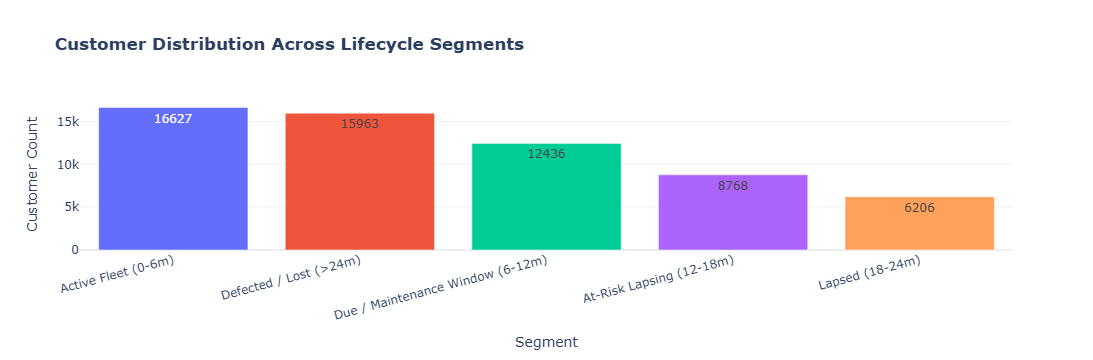

In [5]:
os.makedirs("../docs", exist_ok=True)

fig_seg = px.bar(
    segment_counts,
    x="Segment",
    y="Customer Count",
    title="<b>Customer Distribution Across Lifecycle Segments</b>",
    text="Customer Count",
    template="plotly_white",
    color="Segment"
)
fig_seg.update_layout(xaxis_tickangle=-15, showlegend=False)
fig_seg.write_html("../docs/customer_lifecycle_segments.html")
fig_seg.show()